# Capstone C7 · Mobile manipulation: "bring the green cube to the box"
The Stanford TidyBot (MuJoCo Menagerie): a holonomic base, a 7-DoF Kinova Gen3 arm and a Robotiq 2F-85 gripper.
The cubes are on a table at one end of the room; the box is somewhere else. The robot has to

1. **drive** to the table,
2. **pick the right cube**: a *learned*, language-conditioned skill that looks through a mast camera and the wrist camera,
3. **drive** to the box with the cube,
4. **drop it in.**

This is how most real mobile manipulators are built today: a sequence of skills (System 2 decides which), some
classical (navigation) and some learned (grasping by language). The base parks at the **same** spot in front of the
table every time, so finding the named cube really is the policy's job. Grasping is real friction: no welds here.

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import show_video, show_images, wilson
from vlacourse import showcase as sc
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import train_policy
from vlacourse.lang import TextEmbedder, LangDataset, LangChunkRegression, LangChunkPolicy
from vlacourse.mobile import MobileManip, navigate, pick_pose, ready_arm, PickExpert, collect_picks_parallel, BOX, COLORS, Follow

device = "cuda" if torch.cuda.is_available() else "cpu"
DATA, H = os.path.join("..", "data", "tidybot_pick_v2"), 16
os.makedirs("checkpoints", exist_ok=True); os.makedirs("results", exist_ok=True)

## 1. The room and the robot's cameras

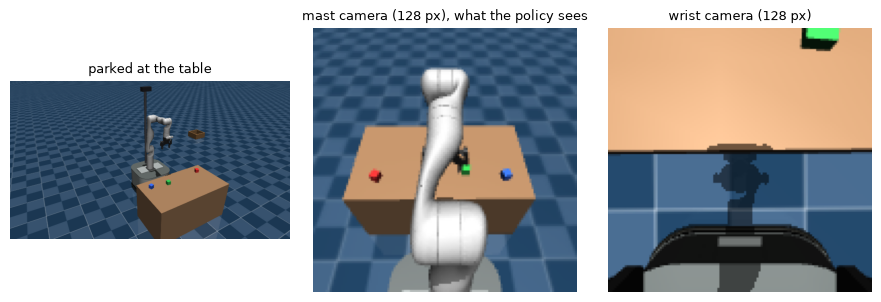

In [2]:
env = MobileManip(cameras=("mast", "wrist"), seed=0)
obs = env.reset(seed=1)
xy, th = pick_pose(env); navigate(env, xy, th); ready_arm(env); obs = env.observe()
show_images([Follow(env).render()[::2, ::2], obs["images"]["mast"], obs["images"]["wrist"]],
            ["parked at the table", "mast camera (128 px), what the policy sees", "wrist camera (128 px)"], cols=3)

## 2. Pick demonstrations
The base drives to the parking spot (not recorded), then a scripted expert picks the instructed cube top-down,
aligned to its yaw. We record the pick: both cameras, the 8-D arm state, the 7-D action (TableTop's convention,
in the base frame). 400 demos, recorded in parallel.

In [3]:
if not os.path.exists(f"{DATA}/meta.json"):
    collect_picks_parallel(DATA, 400, workers=8)
meta = json.load(open(f"{DATA}/meta.json"))
print(f"{meta['n_episodes']} pick demos from {meta['attempts']} attempts, {meta['n_frames']} frames")

400 pick demos from 400 attempts (100%) in 19s with 8 workers
400 pick demos from 400 attempts, 10299 frames


## 3. The pick skill: a language-conditioned chunk policy
The S09 FiLM policy (CLIP text embedding modulates ResNet features of both cameras), 16-step action chunks,
(Our first version used the TidyBot's stock base camera: it sits below the tabletop and sees only the table's side.
The policy was blind, went straight down at the table's centre every time and picked 10%. Check what your cameras see.)
trained on paraphrased instructions ("grab the green cube", "lift the green cube", ...).

In [4]:
emb = TextEmbedder(device=device)
base = TableTopDataset(DATA, episodes=range(360), horizon=H, cameras=("mast", "wrist"), action_mode="delta")
ds = LangDataset(base, emb, paraphrase=True)
net = LangChunkRegression(lang_dim=emb.dim, horizon=H, cameras=("mast", "wrist"), fusion="film")
ckpt = "checkpoints/tidybot_pick_film.pt"
if os.path.exists(ckpt):
    net.load_state_dict(torch.load(ckpt, map_location=device))
else:
    t0 = time.time(); train_policy(net, ds, epochs=40, lr=3e-4, device=device, log_every=10); torch.save(net.state_dict(), ckpt)
    print(f"trained in {time.time() - t0:.0f}s")
net.to(device).eval()
pick_policy = LangChunkPolicy(net, ds, env, emb, device=device, execute=8)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  epoch 10/40  loss 0.0744  (19s)


  epoch 20/40  loss 0.0536  (37s)


  epoch 30/40  loss 0.0435  (51s)


  epoch 40/40  loss 0.0405  (69s)
trained in 69s


## 4. The skills, chained
System 2 here is a simple parser ("bring the X cube to the box" → navigate, pick X, navigate, drop); swap in the
S11 LLM planner for free-form requests. Every stage is checked, so the evaluation can say *which* stage failed.

In [5]:
def fetch(env, seed, frames_cb=None, policy=pick_policy):
    env.reset(seed=seed); c = env.task["obj"]; log = {}
    xy, th = pick_pose(env)
    log["drive to table"] = navigate(env, xy, th, on_step=frames_cb)
    ready_arm(env); env.target, env.target_yaw, env.t = env.pinch_base(), 0.0, 0
    saved = env.task; env.task = dict(type="pick", obj=c, instruction=f"pick up the {c} cube")   # the pick skill's instruction
    policy.reset(); obs = env.observe(); done = False
    while not done:
        obs, _, done, _ = env.step(policy.act(obs))
        if frames_cb: frames_cb(env)
    env.task = saved
    log["pick the right cube"] = env.picked()
    wrong = [o for o in COLORS if o != c and env.cube_pos(o)[2] > 0.53]
    log["(picked a wrong cube)"] = bool(wrong)
    env.retract()
    bx, by = BOX["pos"]
    log["drive to box"] = navigate(env, (bx, by - 0.62), np.pi / 2, on_step=frames_cb)
    tgt = env.to_base(np.array([bx, by, BOX["h"] + 0.15]))
    for _ in range(30):
        env.step(np.r_[np.clip(tgt - env.target, -0.05, 0.05), 0, 0, 0, env.grip])
        if frames_cb: frames_cb(env)
    for _ in range(10):
        env.step(np.r_[0, 0, 0, 0, 0, 0, 0.0])
        if frames_cb: frames_cb(env)
    log["delivered"] = env.delivered()
    return log

t0 = time.time()
logs = [fetch(env, 60_000 + i) for i in range(30)]
k = sum(l["delivered"] for l in logs)
print(f"full fetch: {k}/30 delivered (CI {wilson(k, 30)[0]:.0%}–{wilson(k, 30)[1]:.0%}) ({time.time() - t0:.0f}s)")
for stage in ["drive to table", "pick the right cube", "(picked a wrong cube)", "drive to box", "delivered"]:
    print(f"  {stage:24s} {np.mean([l[stage] for l in logs]):.0%}")

full fetch: 23/30 delivered (CI 59%–88%) (23s)
  drive to table           100%
  pick the right cube      87%
  (picked a wrong cube)    3%
  drive to box             100%
  delivered                77%


## 5. Is the pick skill listening? Same scene, three instructions

In [6]:
def grounding(seed):
    out = {}
    for c in COLORS:
        env.reset(seed=seed); xy, th = pick_pose(env, jitter=False); navigate(env, xy, th)
        ready_arm(env); env.target, env.target_yaw, env.t = env.pinch_base(), 0.0, 0
        env.task = dict(type="pick", obj=c, instruction=f"pick up the {c} cube")
        pick_policy.reset(); obs = env.observe(); done = False
        while not done:
            obs, _, done, _ = env.step(pick_policy.act(obs))
        out[c] = env.picked()
    return out

g = [grounding(61_000 + s) for s in range(8)]
correct = sum(v for d in g for v in d.values())
print(f"grounding: {correct}/{3 * len(g)} instructions picked the named cube (8 scenes × 3 colours)")
json.dump(dict(delivered=k, n=30, stages={s: float(np.mean([l[s] for l in logs])) for s in logs[0]}, grounding=[correct, 3 * len(g)]),
          open("results/C7_fetch.json", "w"), indent=1)

grounding: 20/24 instructions picked the named cube (8 scenes × 3 colours)


## 6. Share-ready video
A camera follows the robot through the room; the wrist camera is inset; the plan ticks off as it goes.

In [7]:
STAGES = ["drive to the table", "pick up the {c} cube", "drive to the box", "drop it in"]
def film(seed):
    """50 fps follow-camera video (rendered during the physics substeps), wrist-camera inset and live plan panel."""
    env.reset(seed=seed); c = env.task["obj"]
    marks, wrists = [], []                                   # (frame index, stage) and (frame index, wrist image)
    def cb(e):
        wrists.append((len(e._vid["frames"]), e.render("wrist")))
    env.start_video(size=(720, 960), fps=50)
    xy, th = pick_pose(env)
    marks.append((0, 0)); navigate(env, xy, th, on_step=cb)
    marks.append((len(env._vid["frames"]), 1))
    ready_arm(env); env.target, env.target_yaw, env.t = env.pinch_base(), 0.0, 0
    env.task = dict(type="pick", obj=c, instruction=f"pick up the {c} cube"); pick_policy.reset(); obs = env.observe(); done = False
    while not done:
        obs, _, done, _ = env.step(pick_policy.act(obs)); cb(env)
    env.retract(); marks.append((len(env._vid["frames"]), 2))
    bx, by = BOX["pos"]; navigate(env, (bx, by - 0.62), np.pi / 2, on_step=cb); marks.append((len(env._vid["frames"]), 3))
    tgt = env.to_base(np.array([bx, by, BOX["h"] + 0.15]))
    for _ in range(30):
        env.step(np.r_[np.clip(tgt - env.target, -0.05, 0.05), 0, 0, 0, env.grip]); cb(env)
    for _ in range(10):
        env.step(np.r_[0, 0, 0, 0, 0, 0, 0.0]); cb(env)
    raw = env.stop_video()
    env.task = dict(type="bring", obj=c, target="box", instruction="")
    ok = env.delivered()
    plan = [st.format(c=c) for st in STAGES]
    out, w = [], 0
    for i, f in enumerate(raw):
        stage = max(s for k, s in marks if k <= i)
        while w + 1 < len(wrists) and wrists[w + 1][0] <= i:
            w += 1
        f = f.copy()
        if wrists:
            f[720 - 256 - 20:720 - 20, 20:276] = np.kron(wrists[w][1], np.ones((2, 2, 1), np.uint8))   # wrist camera inset
        f = sc.caption(f, f"“bring the {c} cube to the box”", where="top", size=26)
        out.append(np.hstack([f, sc.side_panel(plan, stage, size=(720, 320), header="PLAN")]))
    done_panel = np.hstack([out[-1][:, :960], sc.side_panel(plan, 4 if ok else 3, size=(720, 320), header="PLAN")])
    end = sc.badge(done_panel, "✓ delivered" if ok else "✗ not delivered", corner="bl", size=30, color=sc.GOOD if ok else sc.BAD)
    return out + [end] * 60, ok

seed = 60_000 + next((i for i, l in enumerate(logs) if l["delivered"]), 0)
frames, ok = film(seed)
video = sc.title_card("Capstone C7 · Mobile fetch", "drive · pick by language · drive · drop\nMuJoCo · Stanford TidyBot (Menagerie)", size=(720, 1280), n=75) + frames
show_video(video, fps=50, title="C7 mobile fetch HD", width=960)
sc.export(video, "outputs/C7_mobile_fetch.mp4", fps=50)

saved outputs/C7_mobile_fetch.mp4  (8.6 MB)


['outputs/C7_mobile_fetch.mp4']

## Extensions (pick one for your submission)
1. **Crowded room:** add the walking people of S04 project 42b and drive with predictive-sampling MPC instead of `navigate`.
2. **Find the table:** start anywhere and locate the table from the base camera (no known table position).
3. **Two cubes:** "bring the red and the blue cube to the box": the planner must loop, and the arm must not knock the
   second cube off the table while picking the first.
4. **Learn the whole thing:** record full fetch episodes and train one policy that also outputs base velocities.
   Compare with the skill chain: how much data does end-to-end need?